In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.path as mpltPath
import pandas as pd
import random
import cloudpickle as cp
from chainconsumer import ChainConsumer

import torch
import torch.nn as nn

from sbi import __version__ as sbi_version
from sbi.inference import SNPE_C
from sbi.utils import BoxUniform
from sbi import utils
from sbi.utils.get_nn_models import posterior_nn

from src.load_data import load_data_wide
from hyperparameters import hparams

from torch import from_numpy

# Set random seeds for reproducibility
RANDOM_SEED = 42

# Set Python random seed
random.seed(RANDOM_SEED)

# Set NumPy random seed
np.random.seed(RANDOM_SEED)

# Set PyTorch random seed
torch.manual_seed(RANDOM_SEED)

# Set CUDA random seed if available
if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_SEED)
    torch.cuda.manual_seed_all(RANDOM_SEED)
    # Make CUDA operations deterministic (may impact performance)
    #torch.backends.cudnn.deterministic = True
    #torch.backends.cudnn.benchmark = False

# Set environment variable for additional reproducibility
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)

print(f"SBI version: {sbi_version}")
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

if torch.cuda.is_available():
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    print(f"CUDA deterministic: {torch.backends.cudnn.deterministic}")
print(f"Random seed set to: {RANDOM_SEED}")


SBI version: 0.21.0
Using device: cuda
GPU name: NVIDIA A100 80GB PCIe
GPU memory: 85.3 GB
CUDA deterministic: False
Random seed set to: 42


In [2]:
import sys
sys.path.append('./src')

In [2]:
training_parameters, training_data = load_data_wide(hparams)

In [3]:
training_parameters_mean = training_parameters.mean(0)
training_parameters_std = training_parameters.std(0)
training_parameters_stand = (training_parameters - training_parameters_mean) / training_parameters_std

In [10]:
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(training_parameters_stand, training_data)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)

import cloudpickle as cpk
#with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/MSE_Models/3convs_bandwidth2_p63.cpk', 'rb') as f:
with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/MSE_Models/imported_model_1k_examples.cpk', 'rb') as f:
    model = cpk.load(f)

model.to('cuda')

training_data.to('cuda')
print('forward...')
y_pred_stand = model(training_data)

forward...


OutOfMemoryError: CUDA out of memory. Tried to allocate 27.94 GiB (GPU 0; 79.44 GiB total capacity; 61.48 GiB already allocated; 17.44 GiB free; 61.49 GiB reserved in total by PyTorch) If reserved memory is >> allocated memory try setting max_split_size_mb to avoid fragmentation.  See documentation for Memory Management and PYTORCH_CUDA_ALLOC_CONF

In [5]:
y_pred = y_pred_stand[:,:3] *training_parameters_std + training_parameters_mean

In [6]:
sum(p.numel() for p in model.parameters() if p.requires_grad)

103720

In [6]:
# Load measured 2PCFs
#x_train = np.load('./data/2PCF_wide_realization0_mean.npy').reshape(1250, -1)
#x_train = x_train[:, np.where(np.argmax(x_train, axis=0))[0]] #Remove later

'''
# Load cosmological parameters as training data
param_names = ['Om', 'sigma8', 'w0']
param_names_latex = [r"$\Omega_m$", r"$\sigma_8$", r"$w_0$"]
y_train = np.array([np.load('CosmoGrid_params.npz')[par][:1250] for par in param_names]).T
'''



'''
# Convert to tensors
y_train = torch.tensor(y_pred, dtype=torch.float32).to(device=device)
x_train = torch.tensor(training_parameters, dtype=torch.float32).to(device=device)
'''

'''
# Define prior bounds for the parameters (Om, sigma8, w0) as the min and max of the training data
prior_min = y_train.min(0)[0].flatten()
prior_max = y_train.max(0)[0].flatten()
prior = BoxUniform(low=prior_min, high=prior_max, device=device)

# Define the (irregular) boundaries of the parameter space
boundary_Om_sig8 = np.array([
    [0.1, 1.4],
    [0.2, 1.4],
    [0.5, 0.65],
    [0.5, 0.4],
    [0.3, 0.4],
    [0.1, 0.9],])

boundary_Om_w0 = np.array([
    [.1, -1.1],
    [.5, -2.],
    [.5, -.33],
    [.1, -.33],])

# Functions to check if a point is within the given 2D parameter spaces
validOS = mpltPath.Path(boundary_Om_sig8)
validOW = mpltPath.Path(boundary_Om_w0)

# Function to remove points that are outside the parameter space
def remove_invalid_points(samples):
    in_os = validOS.contains_points(samples[:,(0,1)])
    in_ow = validOW.contains_points(samples[:,(0,2)])
    return samples[in_os & in_ow]
'''


/scratch-local/slurm-job-tmp-9673695/ipykernel_5922/2948100049.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_train = torch.tensor(y_pred, dtype=torch.float32).to(device=device)
/scratch-local/slurm-job-tmp-9673695/ipykernel_5922/2948100049.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_train = torch.tensor(training_parameters, dtype=torch.float32).to(device=device)
/home/k/Kai.Lehman/C3NN_inference/sbi/utils/torchutils.py:27: UserWarning: GPU was selected as a device for training the neural network. Note that we expect **no** significant speed ups in training for the default architectures we provide. Using the GPU will be effective only for large neural networks with ope

In [7]:

#lower = np.array([0.1, 0.4, -2.0, 0.87, 0.03, 64.0, 12.0, -2.0])
#upper = np.array([0.5, 1.4, -0.33, 1.07, 0.06, 82.0, 15.0, 2.0])
lower = np.array([0.1, 0.4, -2.0])
upper = np.array([0.5, 1.4, -0.33])
prior = utils.BoxUniform(low=from_numpy(lower), high=from_numpy(upper),device=hparams.device)

# Define the MAF density estimator
density_estimator = posterior_nn(
    model='maf',
    num_transforms=4,         # number of MADEs
    num_blocks=3,             # number of layers in each MADE
    hidden_features=128,      # number of hidden units per layer
)

# Set up SNPE_C with the MAF as density estimator and the compressor as embedding network
#inference = SNPE_C(prior=prior, show_progress_bars=True, density_estimator=density_estimator, device=device)
inference = SNPE_C(prior=prior, show_progress_bars=True, density_estimator=density_estimator, device=device)

_ = inference.append_simulations(training_parameters, y_pred.detach()).train(
    training_batch_size=32, 
    learning_rate=1e-4, 
    stop_after_epochs=20,
    max_num_epochs=1024,
    show_train_summary=True
)

posterior = inference.build_posterior()
# before rerun:
# 101 epochs
# best val 3.9505
# best val 73 epoch, 4.9567

/home/k/Kai.Lehman/C3NN_inference/sbi/utils/torchutils.py:27: UserWarning: GPU was selected as a device for training the neural network. Note that we expect **no** significant speed ups in training for the default architectures we provide. Using the GPU will be effective only for large neural networks with operations that are fast on the GPU, e.g., for a CNN or RNN `embedding_net`.
  warnings.warn(


 Neural network successfully converged after 70 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 70
        Best validation performance: 4.9253
        -------------------------
        
DANGER!!!! No more deepycopy after training!!!


In [13]:
%matplotlib inline

testing_data = np.load("/project/ag-weller/Kai.Lehman/C3NN_data/kappa_noiseless_fiducial_cosmology_150_maps_50_by_50pixels_6_by_6deg_no_smooth_4_des_zsbin_gnom_projection.npy")
testing_data = torch.unsqueeze(torch.tensor(testing_data, dtype=torch.float32).to(device='cuda'),0)
testing_summ_stand = model(testing_data)
testing_summ = testing_summ_stand[:,:3] *training_parameters_std + training_parameters_mean
print(testing_data.shape)
print(testing_summ.shape)
print(testing_summ[0])
samples = posterior.sample((1000000,), x=testing_summ[0,:3]).cpu().numpy()
#samples = remove_invalid_points(samples)
print(samples.shape)

torch.Size([1, 150, 4, 50, 50])
torch.Size([1, 3])
tensor([ 0.2479,  0.8391, -0.9172], device='cuda:0', grad_fn=<SelectBackward0>)


Drawing 1000000 posterior samples:   0%|          | 0/1000000 [00:00<?, ?it/s]

(1000000, 3)


In [9]:
sample_c2_nozscorex_bn_25filter = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/25filters_2order_nozscorex_bn.npy')
sample_c3_nozscorex_bn_25filter = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/25filters_3order_nozscorex_bn.npy')
sample_c4_nozscorex_bn_40filter = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/40filters_4order_nozscorex_bn.npy')
sample_c2_nozscorex_bn_4filter_std = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/4filters_2order_3d_nozscorex_bn_w_std.npy')
sample_c3_nozscorex_bn_25filter_std = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/25filters_3order_3d_nozscorex_bn_w_std.npy')
sample_c4_nozscorex_bn_40filter_std = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/40filters_4order_3d_nozscorex_bn_w_std_nocompression.npy')

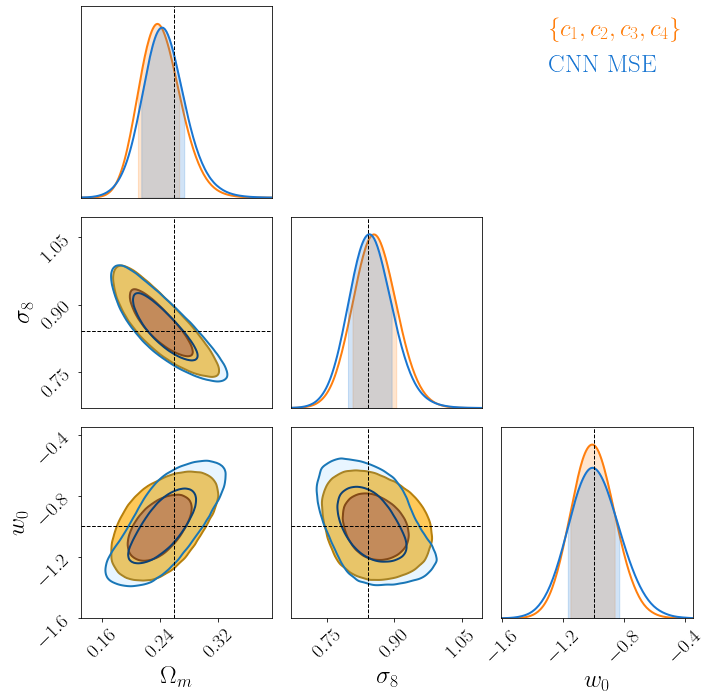

In [17]:
c = ChainConsumer()
c.add_chain(sample_c4_nozscorex_bn_40filter_std[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2, c_3, c_4\}$', shade=True, shade_alpha=0.7, color='#FF7F0E', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(samples[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'CNN MSE', shade=True, shade_alpha=0.1, color='blue', linestyle='-', linewidth=2.0, kde=False)


c.configure_truth(linestyle='dotted', linewidth=0.5)
c.configure(label_font_size=25.0, tick_font_size=20.0, max_ticks=4, summary=False, spacing=2.0, legend_kwargs={'fontsize':25})
fig = c.plotter.plot(figsize=(10, 10), truth=[0.26, 0.84, -1, 0.9649, 0.0493, 67.3, 13.82, 0.0], legend=True)

plt.savefig('Plots/CNN_comp_c4.pdf',bbox_inches='tight')
plt.show()

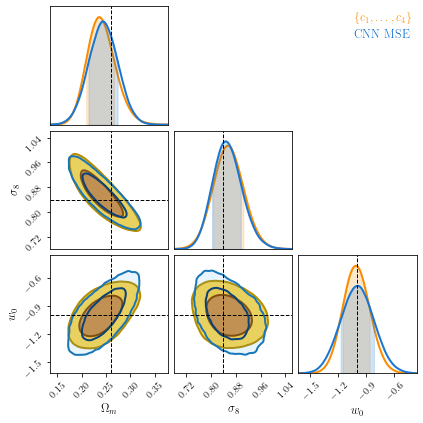

In [22]:
c = ChainConsumer()

#post_df = pd.DataFrame(samples, columns=param_names_latex)
#truth_dict = dict(zip(param_names_latex, y_train[-1]))

#c.add_chain(sample_c2_nozscorex_bn_25filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2\}$ '+'25 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.1, color='purple', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c3_nozscorex_bn_25filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2, c_3\}$ '+'25 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.3, color='green', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c4_nozscorex_bn_40filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_4\}$ '+'40 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.7, color='orange', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2\}$ '+'CNN MSE compression', shade=True, shade_alpha=0.1, color='orange', linestyle='-', linewidth=2.0, kde=False)
'''
c.add_chain(sample_c2_nozscorex_bn_25filter[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2\}$', shade=True, shade_alpha=0.1, color='purple', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(sample_c3_nozscorex_bn_25filter[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2, c_3\}$', shade=True, shade_alpha=0.3, color='green', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(sample_c4_nozscorex_bn_40filter[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, \ldots, c_4\}$', shade=True, shade_alpha=0.7, color='orange', linestyle='-', linewidth=2.0, kde=False)
'''
#c.add_chain(sample_c2_nozscorex_bn_4filter_std[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2\}$', shade=True, shade_alpha=0.1, color='purple', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c3_nozscorex_bn_25filter_std[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2, c_3\}$', shade=True, shade_alpha=0.3, color='green', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(sample_c4_nozscorex_bn_40filter_std[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, \ldots, c_4\}$', shade=True, shade_alpha=0.7, color='orange', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c4_nozscorex_bn_40filter[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, \ldots, c_4\}$', shade=True, shade_alpha=0.7, color='orange', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(samples[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'CNN MSE', shade=True, shade_alpha=0.1, color='blue', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2\}$ '+'CNN MSE compression', shade=True, shade_alpha=0.1, color='orange', linestyle='-', linewidth=2.0, kde=False)


#fig = c.plotter.plot(figsize=(12, 12), truth=[0.26, 0.84, -1, 0.9649, 0.0493, 67.3, 13.82, 0.0], legend=True)
fig = c.plotter.plot(figsize=(6, 6), truth=[0.26, 0.84, -1, 0.9649, 0.0493, 67.3, 13.82, 0.0], legend=True)

#plt.savefig('Plots/CNN_comp_all.png',dpi=400)
#plt.savefig('Plots/some_chains_std.png',dpi=400)
#plt.savefig('Plots/CNN_comp_w_std.pdf')
plt.show()

In [19]:
samples.std(axis=0)

array([0.0286792 , 0.04525944, 0.16127016, 0.04544171, 0.00680878,
       4.125988  , 0.68726945, 0.9372107 ], dtype=float32)

In [17]:
c.analysis.get_summary()

[{'$\\Omega_m$': [0.2247234373773448, 0.2552711484146564, 0.2855760318602565],
  '$\\sigma_8$': [0.7837205289215519, 0.8346665229126728, 0.8902030569984002],
  '$w_0$': [-1.2174274278095727, -1.0787648437790645, -0.9172223048133321]},
 {'$\\Omega_m$': [0.22406454415918414,
   0.25172948829160113,
   0.2807642064435614],
  '$\\sigma_8$': [0.8051456085537412, 0.8521662630954413, 0.8963947172486794],
  '$w_0$': [-1.134327330655187, -0.9786899699570547, -0.8129320778954232]}]

In [14]:
c2_std = sample_c2_nozscorex_bn_25filter[:,:3].std(axis=0)
c3_std = sample_c3_nozscorex_bn_25filter[:,:3].std(axis=0)
c4_std = sample_c4_nozscorex_bn_40filter[:,:3].std(axis=0)

In [23]:
print((c2_std/c3_std).mean())
print((c3_std/c4_std).mean())

1.4897432
1.2263751


In [11]:
c2_std_std = sample_c2_nozscorex_bn_4filter_std[:,:3].std(axis=0)
c3_std_std = sample_c3_nozscorex_bn_25filter_std[:,:3].std(axis=0)
c4_std_std = sample_c4_nozscorex_bn_40filter_std[:,:3].std(axis=0)

In [12]:
print((c2_std_std/c3_std_std).mean())
print((c3_std_std/c4_std_std).mean())

1.3403143
1.1453118


In [15]:
print((c2_std/c2_std_std).mean())
print((c3_std/c3_std_std).mean())
print((c4_std/c4_std_std).mean())

1.2681731
1.1363946
1.0592667
